# Tratamiento de outliers y transformaciones (Issue 6)

**Objetivo:** definir un tratamiento para cada variable numérica, de modo que queden listas para la regresión logística y para el PCA del Issue 7. El PCA es sensible a la escala y a los valores extremos.

Se recorren cinco pasos:

1. Revisar valores extremos, valores imposibles y asimetría.
2. Definir por reglas qué variables reciben winsorización y cuáles `log1p`.
3. Comparar en validación cuatro tratamientos (sin tratar, `log1p`, winsorización, winsorización + `log1p`), cada uno con `RobustScaler` y con `StandardScaler`.
4. Elegir el escalado final.
5. Dejar un pipeline reutilizable para el PCA y para la imputación del Issue 5.

**Reglas:**

- Percentiles, medianas, escalas y la elección de columnas se ajustan solo con `entrenamiento`.
- `validacion` se usa solo para comparar.
- `prueba` no se usa.
- La imputación con la mediana es **provisional**: el pipeline necesita datos sin NaN para entrenar el modelo, pero la imputación definitiva vendrá del Issue 5. `Winsorizador` y `TransformadorLog1p` no imputan; los NaN pasan sin cambios.

El código está en [`src/features.py`](../src/features.py).

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline

sys.path.append(str(Path.cwd().parent))
from src.data import SEED, cargar_prestamos, particionar, separar_X_y
from src.features import (
    LIMITES_WINSOR, EliminadorRedundantes, PreprocesadorNumerico, TransformadorLog1p,
    Winsorizador, construir_preprocesador_numerico, definir_tratamientos, resumen_asimetria,
)

pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 120)

DIR_FIGURAS = Path.cwd().parent / 'reports' / 'figures'
AZUL, NARANJA, TINTA, TINTA_2, REJILLA = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.edgecolor': TINTA_2,
    'axes.labelcolor': TINTA, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'axes.grid': True, 'grid.color': REJILLA, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold',
})

def guardar(fig, nombre):
    fig.savefig(DIR_FIGURAS / nombre, dpi=150, bbox_inches='tight')
    print(f'Figura guardada en reports/figures/{nombre}')

## 1. Datos y columnas del Issue 3

Se cargan con la base común y se aplica el `EliminadorRedundantes` del Issue 3, ajustado con entrenamiento. Se trabaja con las 73 columnas numéricas restantes; la codificación de categóricas no es parte de este issue.

In [2]:
prestamos = cargar_prestamos()
entrenamiento, validacion, _ = particionar(prestamos)   # prueba no se usa
del prestamos
X_ent, y_ent = separar_X_y(entrenamiento)
X_val, y_val = separar_X_y(validacion)
del entrenamiento, validacion

eliminador = EliminadorRedundantes().fit(X_ent, y_ent)
X_ent = eliminador.transform(X_ent).select_dtypes('number')
X_val = eliminador.transform(X_val)[X_ent.columns]
print(f'Entrenamiento: {X_ent.shape}; validación: {X_val.shape}')

Entrenamiento: (862757, 73); validación: (215690, 73)


## 2. Valores extremos y valores imposibles

`resumen_asimetria` calcula, solo con entrenamiento:

- Percentiles 1 y 99.
- `max_sobre_p99`: cuántas veces el máximo supera al percentil 99.
- El porcentaje de valores fuera de [Q1 − 3·IQR, Q3 + 3·IQR].
- Tres asimetrías de Fisher: cruda, recortada a los percentiles 1 y 99, y recortada después de `log1p`.

In [3]:
resumen = resumen_asimetria(X_ent)
resumen.sort_values('max_sobre_p99', ascending=False).head(15).round(2)

,n_unicos,min,p1,mediana,p99,max,max_sobre_p99,pct_fuera_iqr,asim_cruda,asim_recortada,asim_log_recortada
columna,,,,,,,,,,,
tot_coll_amt,10597,0.0,0.00,0.00,4923.00,5252395.0,1066.91,15.35,721.64,5.86,2.14
total_rev_hi_lim,19522,0.0,2800.00,24000.00,157700.00,9999999.0,63.41,2.05,33.13,2.13,-0.16
pub_rec,31,0.0,0.00,0.00,2.00,86.0,43.00,16.91,12.53,2.32,1.98
tax_liens,31,0.0,0.00,0.00,2.00,85.0,42.50,3.19,35.50,6.38,5.80
annual_inc,47492,0.0,18000.00,65000.00,252000.00,9550000.0,37.90,1.64,42.98,1.72,0.09
max_bal_bc,25038,0.0,0.00,4207.00,24374.42,776843.0,31.87,1.50,12.16,1.68,-3.11
revol_bal,73132,0.0,167.56,11129.00,95671.44,2904836.0,30.36,2.31,12.12,2.58,-0.97
dti,6375,-1.0,1.76,17.62,38.46,999.0,25.98,0.12,26.57,0.24,NaN
num_tl_90g_dpd_24m,28,0.0,0.00,0.00,2.00,39.0,19.50,5.73,13.36,4.66,4.17


Varias colas no son ingresos o saldos extremos legítimos, sino valores imposibles o centinelas:

In [4]:
revisiones = {
    'dti = 999 (centinela)': (X_ent['dti'] == 999).sum(),
    'dti > 100': (X_ent['dti'] > 100).sum(),
    'dti < 0': (X_ent['dti'] < 0).sum(),
    'annual_inc = 0': (X_ent['annual_inc'] == 0).sum(),
    'annual_inc > 1 millón': (X_ent['annual_inc'] > 1e6).sum(),
    'revol_util > 100 %': (X_ent['revol_util'] > 100).sum(),
    'total_rev_hi_lim = 9,999,999': (X_ent['total_rev_hi_lim'] == 9_999_999).sum(),
    'tot_hi_cred_lim = 9,999,999': (X_ent['tot_hi_cred_lim'] == 9_999_999).sum(),
    'tot_coll_amt > 100,000': (X_ent['tot_coll_amt'] > 1e5).sum(),
}
pd.Series(revisiones, name='préstamos en entrenamiento').to_frame()

,préstamos en entrenamiento
dti = 999 (centinela),23
dti > 100,330
dti < 0,1
annual_inc = 0,229
annual_inc > 1 millón,189
revol_util > 100 %,3026
"total_rev_hi_lim = 9,999,999",1
"tot_hi_cred_lim = 9,999,999",8
"tot_coll_amt > 100,000",26


Interpretación de estos casos:

- **`dti`:** valores como 999 o mayores a 100 % son imposibles para la razón deuda/ingreso de una solicitud aprobada. Se deben a ingresos casi nulos o a un código de "sin dato".
- **`annual_inc`:** un ingreso de 0 o de varios millones en un préstamo de consumo de hasta 40,000 USD es improbable, y además es un dato autodeclarado.
- **`total_rev_hi_lim` y `tot_hi_cred_lim`:** 9,999,999 es un valor tope del buró.
- **`revol_util`:** puede superar el 100 % legítimamente (sobregiro), pero los valores de 300 % son extremos.

Eliminar estas filas cambiaría la población del Issue 2. Además, en producción también llegarían solicitudes con estos valores. Por eso **no se eliminan filas: se recortan** a percentiles aprendidos en entrenamiento.

## 3. Asimetría y reglas de tratamiento

La asimetría cruda engaña: `tot_coll_amt` tiene 721 por un solo préstamo con 5 millones. Por eso la regla usa la asimetría **recortada** a los percentiles 1 y 99, que mide la forma de la distribución sin unos pocos extremos.

Reglas de `definir_tratamientos`:

1. **Variables binarias:** no se transforman. Ninguna de las 73 lo es.
2. **Winsorización:** se aplica a todas las variables no binarias, con los percentiles 1 y 99 de entrenamiento. Limita centinelas y valores imposibles sin eliminar filas.
3. **`log1p`:** se aplica solo si se cumplen tres condiciones:
   - La variable no tiene negativos.
   - Su asimetría recortada supera 1.
   - El logaritmo la reduce al menos a la mitad en valor absoluto.

La tercera condición evita aplicar logaritmos donde no ayudan:

- **`fico_range_low`:** su rango es estrecho (615–845) y el logaritmo apenas cambia la asimetría (1.19 → 1.08).
- **Conteos con muchos ceros** (`pub_rec`, `delinq_2yrs`, `tax_liens`): su asimetría viene de la masa en cero, que el logaritmo no corrige.
- **Variables donde el logaritmo invierte la asimetría** (`max_bal_bc`: 1.68 → −3.11).

In [5]:
tratamientos = definir_tratamientos(resumen)
tabla = resumen[['min', 'mediana', 'p1', 'p99', 'max', 'asim_cruda', 'asim_recortada', 'asim_log_recortada']].join(tratamientos['tratamiento'])
print(tratamientos['tratamiento'].value_counts().to_string())
tabla.sort_values('asim_recortada', ascending=False).round(2)

tratamiento
winsorización            40
winsorización + log1p    33


,min,mediana,p1,p99,max,asim_cruda,asim_recortada,asim_log_recortada,tratamiento
columna,,,,,,,,,
collections_12_mths_ex_med,0.0,0.00,0.00,1.00,14.00,13.32,7.80,7.80,winsorización
tax_liens,0.0,0.00,0.00,2.00,85.00,35.50,6.38,5.80,winsorización
sec_app_chargeoff_within_12_mths,0.0,0.00,0.00,2.00,20.00,18.14,6.33,5.76,winsorización
tot_coll_amt,0.0,0.00,0.00,4923.00,5252395.00,721.64,5.86,2.14,winsorización + log1p
num_tl_90g_dpd_24m,0.0,0.00,0.00,2.00,39.00,13.36,4.66,4.17,winsorización
sec_app_collections_12_mths_ex_med,0.0,0.00,0.00,2.00,16.00,12.28,4.33,3.85,winsorización
num_accts_ever_120_pd,0.0,0.00,0.00,6.00,51.00,5.10,3.04,1.92,winsorización
delinq_2yrs,0.0,0.00,0.00,4.00,39.00,5.67,3.03,2.11,winsorización
mths_since_rcnt_il,0.0,12.00,1.00,129.00,488.00,3.51,2.81,0.27,winsorización + log1p


Figura guardada en reports/figures/outliers_asimetria.png


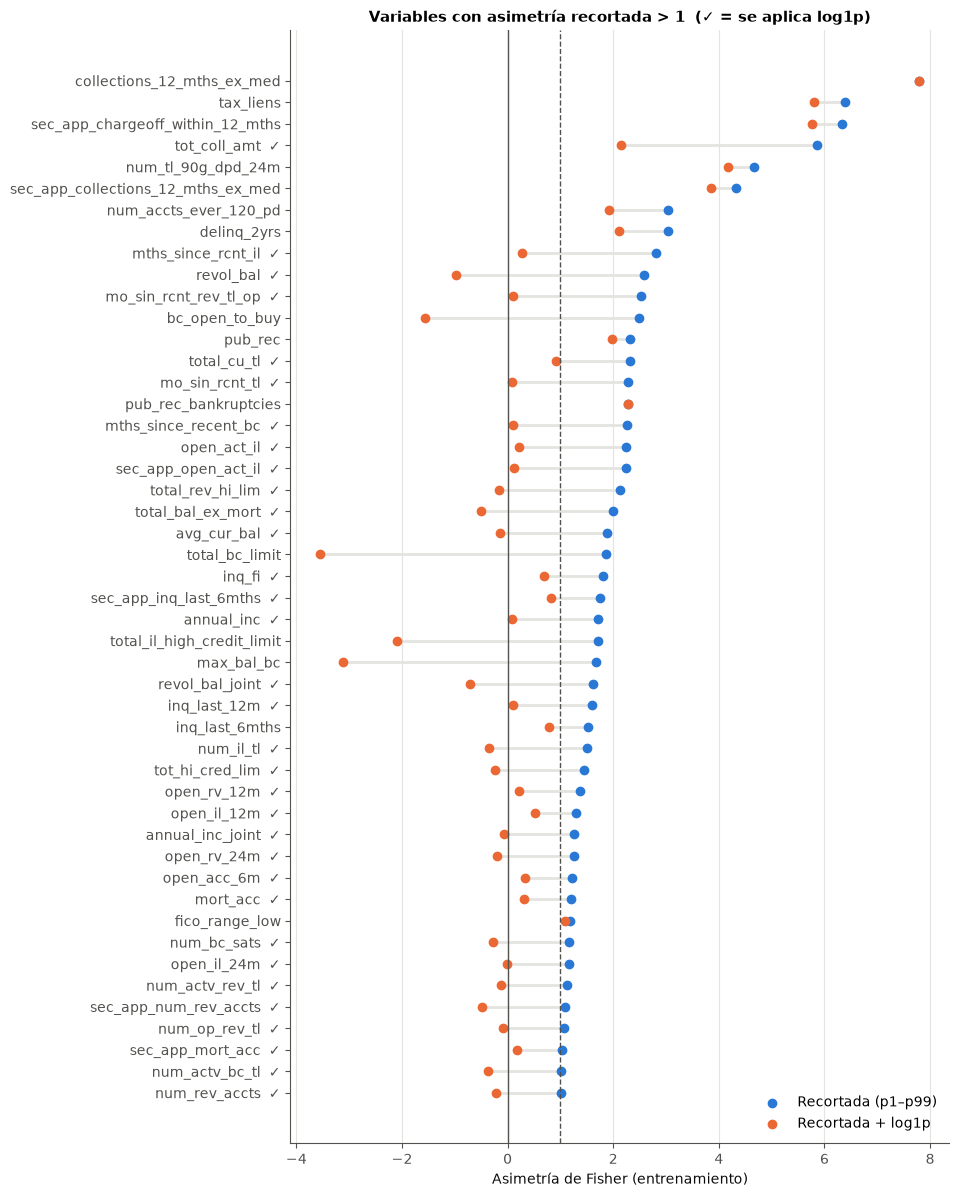

In [6]:
asimetricas = resumen.loc[resumen['asim_recortada'] > 1].sort_values('asim_recortada')
log_si = tratamientos.loc[asimetricas.index, 'log1p']
fig, ax = plt.subplots(figsize=(8.5, 0.27 * len(asimetricas) + 1.5))
posiciones = np.arange(len(asimetricas))
for y_pos, (col, fila) in zip(posiciones, asimetricas.iterrows()):
    ax.plot([fila['asim_recortada'], fila['asim_log_recortada']], [y_pos, y_pos], color=REJILLA, linewidth=2, zorder=1)
ax.scatter(asimetricas['asim_recortada'], posiciones, color=AZUL, s=36, zorder=2, label='Recortada (p1–p99)')
ax.scatter(asimetricas['asim_log_recortada'], posiciones, color=NARANJA, s=36, zorder=2, label='Recortada + log1p')
ax.set_yticks(posiciones, [f'{c}  ✓' if log_si[c] else c for c in asimetricas.index])
ax.axvline(0, color=TINTA_2, linewidth=1)
ax.axvline(1, color=TINTA_2, linewidth=1, linestyle='--')
ax.set_xlabel('Asimetría de Fisher (entrenamiento)')
ax.set_title('Variables con asimetría recortada > 1  (✓ = se aplica log1p)')
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right', frameon=False)
guardar(fig, 'outliers_asimetria.png')
plt.show()

## 4. Antes y después en variables clave

Se ajusta `PreprocesadorNumerico` sin escalado ni imputación, para ver solo el efecto de la winsorización y de `log1p` sobre la distribución.

Los NaN quedan en las mismas posiciones: el tratamiento no imputa.
Figura guardada en reports/figures/outliers_antes_despues.png


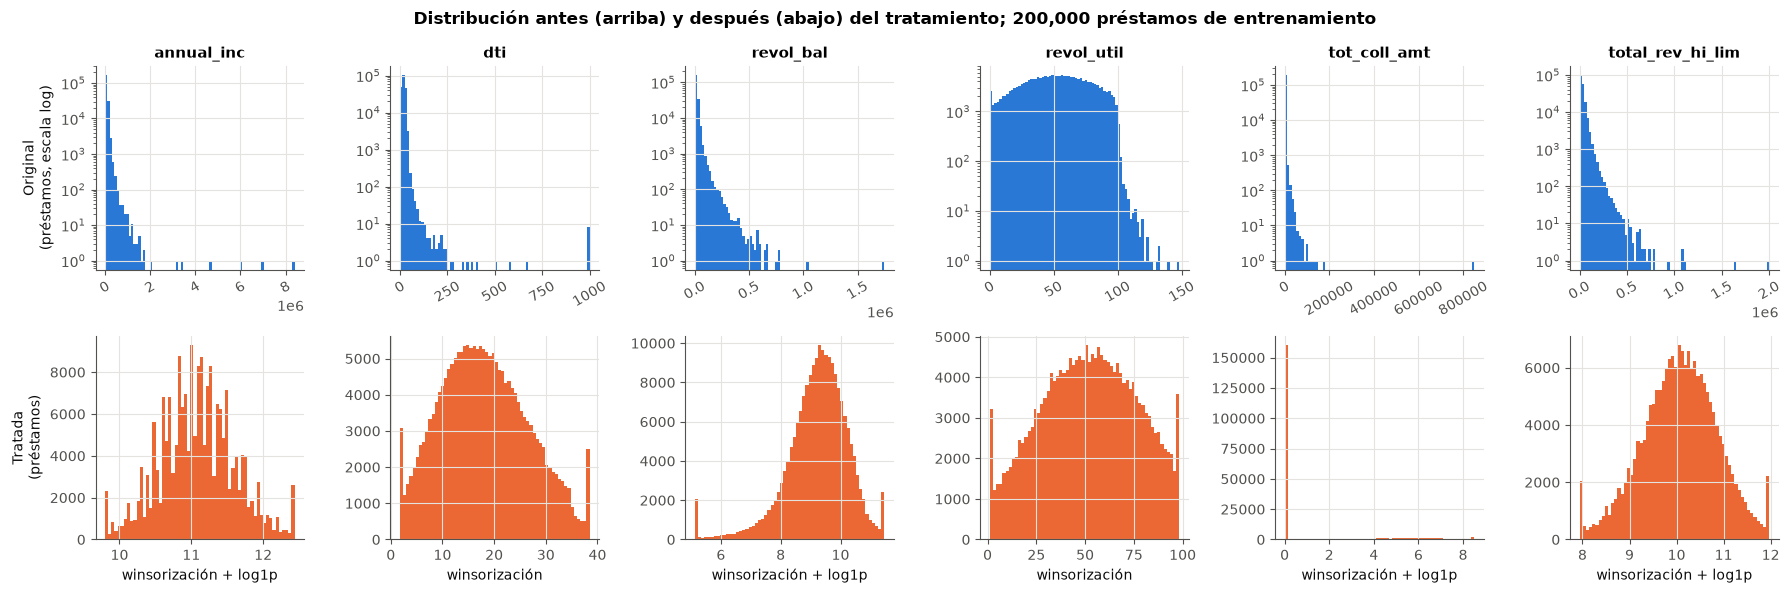

In [7]:
solo_forma = PreprocesadorNumerico(escalador=None, imputador=None).fit(X_ent)
X_ent_forma = solo_forma.transform(X_ent)
assert X_ent_forma.isna().equals(X_ent.isna()), 'Los NaN deben pasar sin cambios'
print('Los NaN quedan en las mismas posiciones: el tratamiento no imputa.')

CLAVE = ['annual_inc', 'dti', 'revol_bal', 'revol_util', 'tot_coll_amt', 'total_rev_hi_lim']
muestra = X_ent.sample(200_000, random_state=SEED).index
fig, ejes = plt.subplots(2, len(CLAVE), figsize=(18, 6))
for j, col in enumerate(CLAVE):
    original = X_ent.loc[muestra, col].dropna()
    tratada = X_ent_forma.loc[muestra, col].dropna()
    ejes[0, j].hist(original, bins=80, color=AZUL)
    ejes[0, j].set_yscale('log')
    ejes[0, j].set_title(col)
    ejes[1, j].hist(tratada, bins=60, color=NARANJA)
    ejes[1, j].set_xlabel(tratamientos.loc[col, 'tratamiento'])
    ejes[0, j].tick_params(axis='x', labelrotation=30)
ejes[0, 0].set_ylabel('Original\n(préstamos, escala log)')
ejes[1, 0].set_ylabel('Tratada\n(préstamos)')
fig.suptitle('Distribución antes (arriba) y después (abajo) del tratamiento; 200,000 préstamos de entrenamiento', fontweight='bold')
fig.tight_layout()
guardar(fig, 'outliers_antes_despues.png')
plt.show()

Figura guardada en reports/figures/outliers_boxplots.png


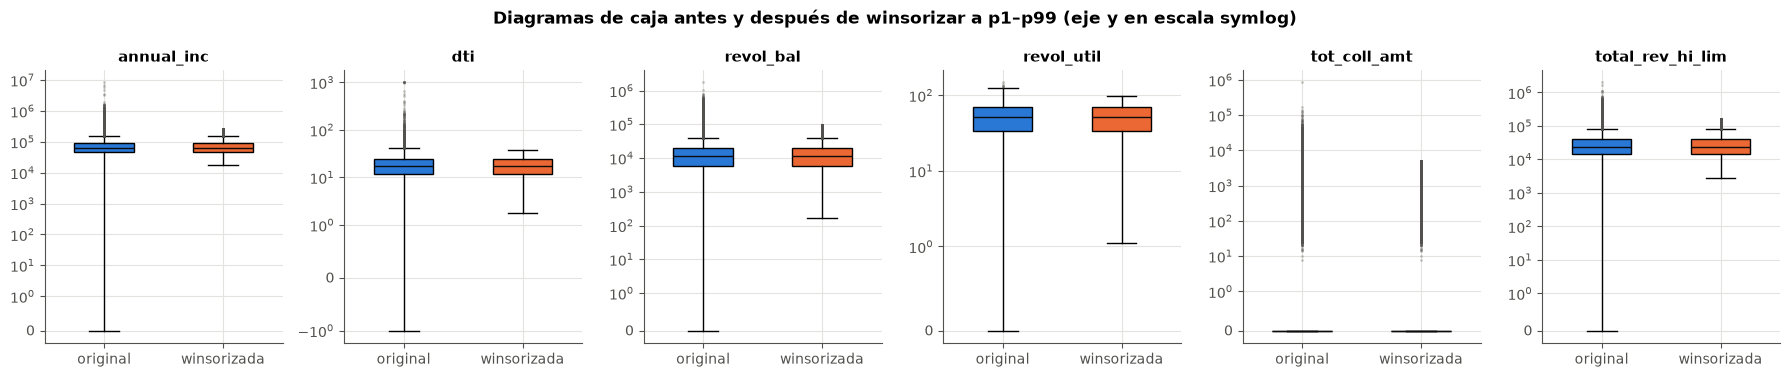

,inferior,superior,pct_recortado_ent
annual_inc,18000.00,252000.00,1.93
dti,1.76,38.46,1.99
revol_bal,167.56,95671.44,2.00
revol_util,1.10,98.30,1.95
tot_coll_amt,0.00,4923.00,0.95
total_rev_hi_lim,2800.00,157700.00,1.86


In [8]:
fig, ejes = plt.subplots(1, len(CLAVE), figsize=(18, 3.8))
winsor = solo_forma.pipeline_.named_steps['winsorizacion']
for ax, col in zip(ejes, CLAVE):
    original = X_ent.loc[muestra, col].dropna()
    recortada = original.clip(*winsor.limites_.loc[col])
    caja = ax.boxplot([original, recortada], tick_labels=['original', 'winsorizada'], widths=0.5,
                      patch_artist=True, flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.3, 'markeredgecolor': TINTA_2},
                      medianprops={'color': TINTA})
    for parche, color in zip(caja['boxes'], [AZUL, NARANJA]):
        parche.set_facecolor(color)
    ax.set_yscale('symlog', linthresh=1)
    ax.set_title(col)
fig.suptitle('Diagramas de caja antes y después de winsorizar a p1–p99 (eje y en escala symlog)', fontweight='bold')
fig.tight_layout()
guardar(fig, 'outliers_boxplots.png')
plt.show()

winsor.limites_.loc[CLAVE].assign(
    pct_recortado_ent=[((X_ent[c] < winsor.limites_.loc[c, 'inferior']) | (X_ent[c] > winsor.limites_.loc[c, 'superior'])).mean() * 100 for c in CLAVE],
).round(2)

## 5. Comparación en validación

Se entrena la misma regresión logística del baseline (`max_iter=1000`, `random_state=42`) con 8 preprocesamientos: 4 tratamientos × 2 escaladores. Todos incluyen la imputación provisional con la mediana. Se usan dos conjuntos de variables:

- **Baseline (9 variables):** permite comparar con la referencia del Issue 2 (validación: ROC-AUC 0.6336, PR-AUC 0.2855). La fila "sin tratar + standard" debe reproducirla exactamente.
- **Numéricas tras el Issue 3 (73 variables):** el conjunto que recibirá el PCA.

Las columnas que reciben cada tratamiento salen de la tabla de la sección 3, calculada solo con entrenamiento.

In [9]:
BASELINE = ['annual_inc', 'dti', 'open_acc', 'pub_rec', 'revol_bal',
            'total_acc', 'fico_range_low', 'delinq_2yrs', 'inq_last_6mths']
CONJUNTOS = {'Baseline (9)': BASELINE, 'Numéricas Issue 3 (73)': list(X_ent.columns)}
TRATAMIENTOS = {
    'sin tratar': (False, False),
    'log1p': (True, False),
    'winsorización': (False, True),
    'winsorización + log1p': (True, True),
}

def evaluar(columnas, usar_log, usar_winsor, escalador):
    trat = tratamientos.loc[columnas]
    preprocesador = construir_preprocesador_numerico(
        columnas_log=list(trat.index[trat['log1p']]) if usar_log else [],
        columnas_winsor=list(trat.index[trat['winsor']]) if usar_winsor else [],
        escalador=escalador,
    )
    modelo = Pipeline([('pre', preprocesador), ('modelo', LogisticRegression(max_iter=1000, random_state=SEED))])
    inicio = time.time()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always', ConvergenceWarning)
        modelo.fit(X_ent[columnas], y_ent)
    prob = modelo.predict_proba(X_val[columnas])[:, 1]
    return {
        'ROC-AUC': roc_auc_score(y_val, prob),
        'PR-AUC': average_precision_score(y_val, prob),
        'iteraciones': int(modelo.named_steps['modelo'].n_iter_[0]),
        'convergió': not any(issubclass(a.category, ConvergenceWarning) for a in avisos),
        'segundos': round(time.time() - inicio, 1),
    }

filas = []
for conjunto, columnas in CONJUNTOS.items():
    for tratamiento, (usar_log, usar_winsor) in TRATAMIENTOS.items():
        for escalador in ('standard', 'robust'):
            filas.append({'conjunto': conjunto, 'tratamiento': tratamiento, 'escalador': escalador,
                          **evaluar(columnas, usar_log, usar_winsor, escalador)})
comparacion = pd.DataFrame(filas).set_index(['conjunto', 'tratamiento', 'escalador'])
comparacion.round(4)

ROC-AUC  PR-AUC  iteraciones  convergió  segundos
conjunto               tratamiento           escalador                                                   
Baseline (9)           sin tratar            standard    0.6336  0.2855            9       True       1.2
                                             robust      0.6336  0.2855           12       True       1.8
                       log1p                 standard    0.6342  0.2845            9       True       1.2
                                             robust      0.6343  0.2846           10       True       1.4
                       winsorización         standard    0.6356  0.2887            9       True       1.3
                                             robust      0.6356  0.2888           11       True       1.9
                       winsorización + log1p standard    0.6362  0.2881           10       True       1.7
                                             robust      0.6362  0.2881           10       True       1.7
Numéricas Issue 3 (73) sin tratar            standard    0.6565  0.3090           26       True       8.7
                                             robust      0.5931  0.2564         1000      False     139.7
                       log1p                 standard    0.6586  0.3101           24       True       8.2
                                             robust      0.6529  0.3049         1000      False     150.8
                       winsorización         standard    0.6586  0.3141           28       True       9.7
                                             robust      0.6010  0.2660         1000      False     135.6
                       winsorización + log1p standard    0.6607  0.3153           36       True      11.4
                                             robust      0.6547  0.3092         1000      False     136.9

Figura guardada en reports/figures/outliers_comparacion_validacion.png


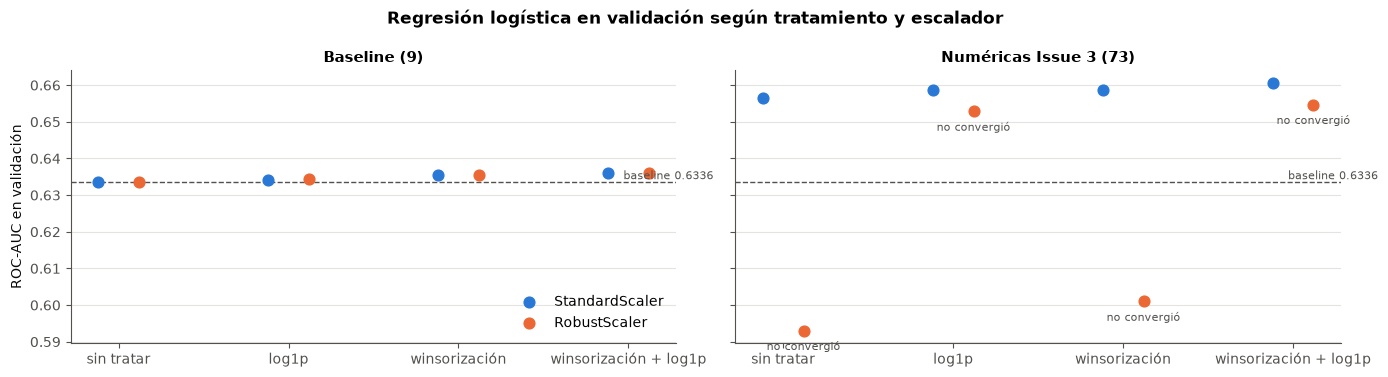

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
orden = list(TRATAMIENTOS)
for ax, conjunto in zip(ejes, CONJUNTOS):
    datos = comparacion.loc[conjunto]
    for desplazamiento, escalador, color in ((-0.12, 'standard', AZUL), (0.12, 'robust', NARANJA)):
        valores = datos.xs(escalador, level='escalador').loc[orden]
        posiciones = np.arange(len(orden)) + desplazamiento
        ax.scatter(posiciones, valores['ROC-AUC'], color=color, s=60, zorder=3,
                   label=f'{escalador.capitalize()}Scaler')
        for x, (_, fila) in zip(posiciones, valores.iterrows()):
            if not fila['convergió']:
                ax.annotate('no convergió', (x, fila['ROC-AUC']), textcoords='offset points', xytext=(0, -14),
                            ha='center', fontsize=8, color=TINTA_2)
    ax.axhline(0.6336, color=TINTA_2, linestyle='--', linewidth=1)
    ax.text(len(orden) - 0.5, 0.6336, 'baseline 0.6336', ha='right', va='bottom', fontsize=8, color=TINTA_2)
    ax.set_xticks(range(len(orden)), orden)
    ax.set_title(conjunto)
    ax.grid(axis='x', visible=False)
ejes[0].set_ylabel('ROC-AUC en validación')
ejes[0].legend(loc='lower right', frameon=False)
fig.suptitle('Regresión logística en validación según tratamiento y escalador', fontweight='bold')
fig.tight_layout()
guardar(fig, 'outliers_comparacion_validacion.png')
plt.show()

### ¿Por qué `RobustScaler` no converge con 73 variables?

`RobustScaler` resta la mediana y divide por el rango intercuartílico (IQR). Si el IQR es 0, scikit-learn usa escala 1, es decir, deja la columna en sus unidades originales. Aquí ocurre en muchas columnas, por dos motivos:

- **Conteos con más del 75 % de ceros:** Q1 = Q3 = 0.
- **Columnas con más del 50 % de nulos:** tras imputar con la mediana, más de la mitad de los valores son idénticos y el IQR se anula. Pasa con el bloque de 2016 en adelante, `mths_since_*`, `*_joint` y `sec_app_*`.

Esas columnas quedan con escalas muy distintas a las demás. El problema queda mal condicionado y L-BFGS agota las 1000 iteraciones.

In [11]:
pre_robust = PreprocesadorNumerico(escalador='robust').fit(X_ent)
escala = pd.Series(pre_robust.pipeline_.named_steps['escalado'].scale_, index=X_ent.columns)
iqr_cero = escala.index[escala == 1.0]
desviaciones = pre_robust.transform(X_ent).std()
print(f'Columnas con IQR = 0 tras imputar (RobustScaler no las escala): {len(iqr_cero)} de {X_ent.shape[1]}')
print(f'Desviación estándar tras RobustScaler: mínima {desviaciones.min():.3f}, máxima {desviaciones.max():,.1f} ({desviaciones.idxmax()})')
desviaciones.sort_values(ascending=False).head(6).round(2).to_frame('desviación tras RobustScaler')

Columnas con IQR = 0 tras imputar (RobustScaler no las escala): 40 de 73
Desviación estándar tras RobustScaler: mínima 0.030, máxima 3,086.2 (max_bal_bc)


,desviación tras RobustScaler
max_bal_bc,3086.20
mths_since_last_delinq,15.44
il_util,13.25
all_util,13.02
mths_since_recent_revol_delinq,12.89
mths_since_last_record,11.01


Este hallazgo decide el escalado:

- **`RobustScaler` no sirve para este conjunto.** Su ventaja, la robustez frente a extremos, ya la aporta la winsorización. Su desventaja, no escalar columnas con IQR = 0, rompe el modelo con 73 variables.
- **El PCA del Issue 7 necesita `StandardScaler`.** El PCA maximiza la varianza, así que todas las columnas deben entrar con varianza 1. Con `RobustScaler`, `max_bal_bc` dominaría los primeros componentes solo por su escala.

## 6. Pipeline final

**Tratamiento elegido: winsorización a p1–p99 + `log1p` en las variables asimétricas + imputación provisional con la mediana + `StandardScaler`.** Es la configuración por defecto de `PreprocesadorNumerico`.

In [12]:
preprocesador = PreprocesadorNumerico().fit(X_ent)   # fit solo con entrenamiento
Z_ent = preprocesador.transform(X_ent)
Z_val = preprocesador.transform(X_val)
print('Pasos:', [nombre for nombre, _ in preprocesador.pipeline_.steps])
print(f'Columnas con log1p: {len(preprocesador.columnas_log_)}; con winsorización: {len(preprocesador.columnas_winsor_)}')
print(f'NaN tras el pipeline -> entrenamiento: {Z_ent.isna().sum().sum()}, validación: {Z_val.isna().sum().sum()}')
print(f'Entrenamiento: medias en [{Z_ent.mean().min():.1e}, {Z_ent.mean().max():.1e}], desviaciones en [{Z_ent.std().min():.4f}, {Z_ent.std().max():.4f}]')
print(f'Validación (sin reajustar): medias en [{Z_val.mean().min():.3f}, {Z_val.mean().max():.3f}], desviaciones en [{Z_val.std().min():.3f}, {Z_val.std().max():.3f}]')

Pasos: ['winsorizacion', 'log1p', 'imputacion_provisional', 'escalado']
Columnas con log1p: 33; con winsorización: 73
NaN tras el pipeline -> entrenamiento: 0, validación: 0
Entrenamiento: medias en [-3.6e-14, 1.4e-14], desviaciones en [1.0000, 1.0000]
Validación (sin reajustar): medias en [-0.006, 0.004], desviaciones en [0.954, 1.030]


Las medias y desviaciones de validación quedan cerca de 0 y 1 sin reajustar el pipeline: los percentiles, las medianas y las escalas de entrenamiento se aplican tal cual.

Por último, se comprueba que el pipeline admite cualquier imputador. Con `imputador=None` los NaN llegan intactos al escalador, porque `StandardScaler` los ignora al ajustar y los conserva al transformar. Así, el imputador del Issue 5 puede ir en ese lugar:

```python
PreprocesadorNumerico(imputador=imputador_issue_5)
```

In [13]:
sin_imputar = PreprocesadorNumerico(imputador=None).fit(X_ent)
Z_nan = sin_imputar.transform(X_val)
assert Z_nan.isna().equals(X_val.isna())
print('Sin imputador: los NaN de validación se conservan en las mismas posiciones.')

Sin imputador: los NaN de validación se conservan en las mismas posiciones.


## 7. Conclusiones

**Tratamiento definido para las 73 variables numéricas**, aprendido solo con entrenamiento:

| Tratamiento | Columnas | Criterio |
|---|---|---|
| Winsorización p1–p99 + `log1p` | 33: `annual_inc`, `revol_bal`, `total_rev_hi_lim`, `tot_hi_cred_lim`, `tot_coll_amt`, `avg_cur_bal`, `total_bal_ex_mort`, los conteos de cuentas abiertas y consultas, entre otras | Sin negativos; asimetría recortada > 1; el logaritmo la reduce al menos a la mitad |
| Solo winsorización p1–p99 | 40: `dti`, `revol_util`, `fico_range_low`, `pub_rec`, `delinq_2yrs`, `max_bal_bc`, `bc_open_to_buy`, `mths_since_*`, entre otras | Distribución casi simétrica, negativos (`dti`), o el logaritmo no mejora o invierte la asimetría |
| Escalado | todas | `StandardScaler`, después de la imputación provisional |

Resultados en validación:

- **El tratamiento mejora al modelo sin tratar** (ROC-AUC / PR-AUC):
  - Con las 73 numéricas: de 0.6565 / 0.3090 a 0.6607 / 0.3153.
  - Con las 9 variables del baseline: de 0.6336 / 0.2855 a 0.6362 / 0.2881.
  - La winsorización aporta la mayor parte de la mejora en PR-AUC, y `log1p` la complementa en ROC-AUC.
- **`StandardScaler` es el escalado final.** `RobustScaler` da el mismo resultado con 9 variables, pero con 73 no converge en ninguna configuración y empeora (hasta 0.5931). En 40 de las 73 columnas el IQR es 0 —conteos con muchos ceros, o columnas con más de 50 % de nulos imputadas con la mediana—, así que `RobustScaler` las deja sin escalar. Además, el PCA necesita varianza 1 en todas las columnas.
- **No se eliminan filas.** Los centinelas e imposibles (`dti = 999`, `annual_inc = 0`, límites de 9,999,999) se recortan a percentiles de entrenamiento: entre 1 % y 2 % de recorte por variable.
- **Los NaN se respetan:** `Winsorizador` y `TransformadorLog1p` los dejan pasar. La mediana es provisional y se reemplaza con `PreprocesadorNumerico(imputador=...)` cuando el Issue 5 defina la imputación.

Para el PCA (Issue 7):

```python
from src.features import EliminadorRedundantes, PreprocesadorNumerico
eliminador = EliminadorRedundantes().fit(X_entrenamiento, y_entrenamiento)
preprocesador = PreprocesadorNumerico().fit(eliminador.transform(X_entrenamiento))
Z_entrenamiento = preprocesador.transform(eliminador.transform(X_entrenamiento))
Z_validacion = preprocesador.transform(eliminador.transform(X_validacion))
```